<a href="https://colab.research.google.com/github/ngocngangiang68/AI-project-final/blob/feature%2Fdata-preprocessing-and-feature%2Fcnn-models/student_face_attendance_(2)_(1)_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Tìm tất cả ảnh trong dataset
image_files = [
    p for p in extract_path.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Tổng số ảnh:", len(image_files))

print("\n5 ảnh đầu tiên:")
for img in image_files[:5]:
    print(img)


Tổng số ảnh: 0

5 ảnh đầu tiên:


In [ ]:
import zipfile
from pathlib import Path

# Lấy đường dẫn thư mục đang chạy Jupyter
BASE_DIR = Path.cwd()

# Đường dẫn file ZIP
zip_path = BASE_DIR / "archive.zip"

# Thư mục lưu dataset sau khi giải nén
extract_path = BASE_DIR / "data" / "kaggle"

# Tạo thư mục nếu chưa tồn tại
extract_path.mkdir(parents=True, exist_ok=True)

# Kiểm tra và giải nén
if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Giải nén dataset thành công!")
    print("Thư mục lưu:", extract_path)
else:
    print("Không tìm thấy file archive.zip!")
    print("Hãy kiểm tra đường dẫn:", zip_path)


Không tìm thấy file archive.zip!
Hãy kiểm tra đường dẫn: /content/archive.zip


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Section 2 – Dataset Loading & Exploration

In [ ]:

import pandas as pd
from pathlib import Path

# Lấy tên thư mục cha của từng ảnh làm identity
identity_counts = {}

for img_path in image_files:
    identity = img_path.parent.name

    if identity not in identity_counts:
        identity_counts[identity] = 0

    identity_counts[identity] += 1

# Tạo bảng thống kê
df = pd.DataFrame(
    list(identity_counts.items()),
    columns=["Identity", "Number of Images"]
)

# Sắp xếp theo số ảnh giảm dần
df = df.sort_values(
    by="Number of Images",
    ascending=False
).reset_index(drop=True)

print("Total identities:", len(df))
print("Total images:", df["Number of Images"].sum())

display(df.head(20))


Total identities: 0
Total images: 0


,Identity,Number of Images


In [ ]:

import pandas as pd
from pathlib import Path

# Lấy tên thư mục cha của từng ảnh làm identity
identity_counts = {}

for img_path in image_files:
    identity = img_path.parent.name

    if identity not in identity_counts:
        identity_counts[identity] = 0

    identity_counts[identity] += 1

# Tạo bảng thống kê
df = pd.DataFrame(
    list(identity_counts.items()),
    columns=["Identity", "Number of Images"]
)

# Sắp xếp theo số ảnh giảm dần
df = df.sort_values(
    by="Number of Images",
    ascending=False
).reset_index(drop=True)

print("Total identities:", len(df))
print("Total images:", df["Number of Images"].sum())

display(df.head(20))


Total identities: 0
Total images: 0


,Identity,Number of Images


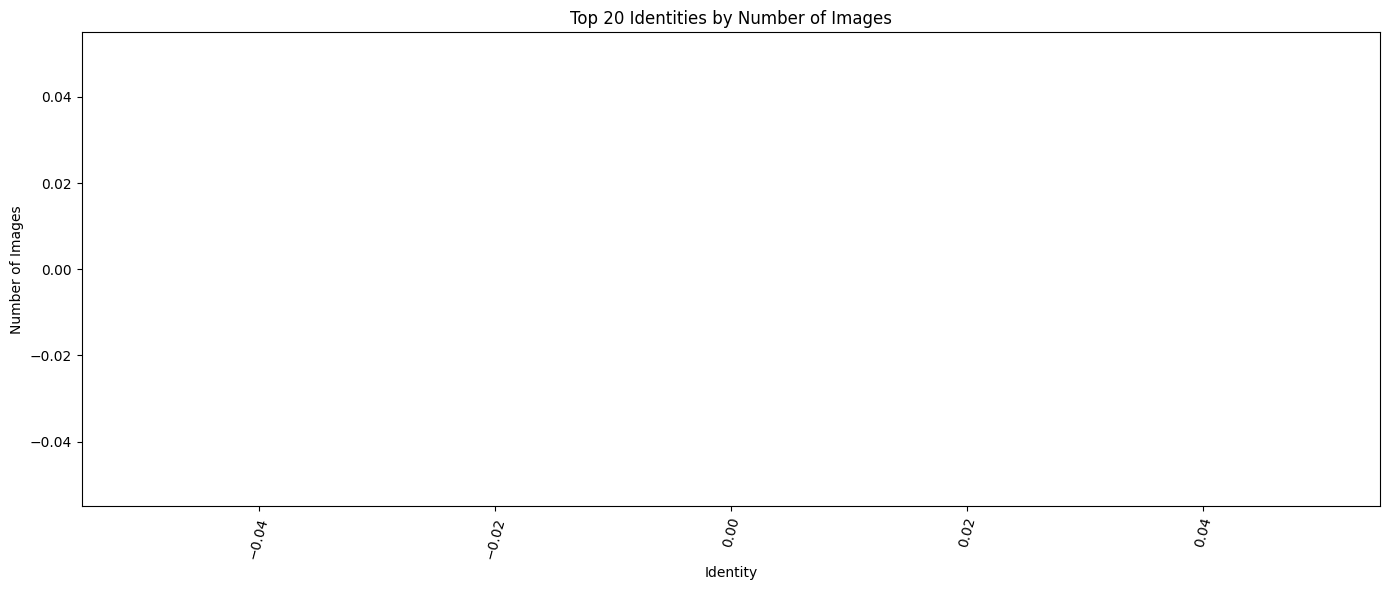

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    df["Identity"].head(20),
    df["Number of Images"].head(20)
)

plt.title("Top 20 Identities by Number of Images")
plt.xlabel("Identity")
plt.ylabel("Number of Images")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


In [ ]:

import random
from PIL import Image

random.seed(42)

sample_images = random.sample(
    image_files,
    min(9, len(image_files))
)

plt.figure(figsize=(10, 10))

for i, img_path in enumerate(sample_images):
    img = Image.open(img_path).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(img_path.parent.name, fontsize=9)
    plt.axis("off")

plt.suptitle("Sample Images from Kaggle Dataset")
plt.tight_layout()
plt.show()


<Figure size 1000x1000 with 0 Axes>

In [ ]:

from PIL import Image
import pandas as pd

image_info = []

for img_path in image_files:
    try:
        with Image.open(img_path) as img:
            width, height = img.size

        image_info.append({
            "identity": img_path.parent.name,
            "width": width,
            "height": height,
            "path": str(img_path)
        })

    except Exception:
        continue

quality_df = pd.DataFrame(image_info)

print("Total valid images:", len(quality_df))

print("\nImage size statistics:")
display(quality_df[["width", "height"]].describe())

# Đếm ảnh có kích thước quá nhỏ
small_images = quality_df[
    (quality_df["width"] < 80) |
    (quality_df["height"] < 80)
]

print("Images with small dimensions:", len(small_images))
print(
    "Percentage:",
    round(len(small_images) / len(quality_df) * 100, 2),
    "%"
)


Total valid images: 0

Image size statistics:


KeyError: "None of [Index(['width', 'height'], dtype='object')] are in the [columns]"

In [ ]:

%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install --no-cache-dir --force-reinstall --no-deps opencv-python==4.10.0.84


In [ ]:

# SECTION 2 - IMAGE QUALITY FILTERING

# Chỉ giữ ảnh có cả chiều rộng và chiều cao >= 80
filtered_df = quality_df[
    (quality_df["width"] >= 80) &
    (quality_df["height"] >= 80)
].copy()

print("Original images:", len(quality_df))
print("Filtered images:", len(filtered_df))
print("Removed images:", len(quality_df) - len(filtered_df))

# Thống kê số ảnh còn lại của từng identity
identity_quality = (
    filtered_df.groupby("identity")
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

print("\nIdentities with at least 105 images:")

eligible_identities = identity_quality[
    identity_quality["image_count"] >= 105
]

print("Total eligible identities:", len(eligible_identities))

display(eligible_identities.head(20))


In [ ]:

%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install --no-cache-dir --force-reinstall --no-deps opencv-python==4.10.0.84


In [ ]:

import cv2

print("OpenCV version:", cv2.__version__)

print(
    "CascadeClassifier exists:",
    hasattr(cv2, "CascadeClassifier")
)

cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(cascade_path)

print("Haar Cascade loaded:", not face_cascade.empty())


In [ ]:

import cv2
import random
import matplotlib.pyplot as plt
from pathlib import Path

# Đường dẫn dataset Kaggle
dataset_dir = Path("data/kaggle")

# Lấy danh sách ảnh
image_files = [
    p for p in dataset_dir.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Total images:", len(image_files))

# Chọn ngẫu nhiên 10 ảnh
random.seed(42)
sample_paths = random.sample(image_files, 10)

# Hiển thị kết quả phát hiện khuôn mặt
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

success_count = 0

for ax, path in zip(axes.flat, sample_paths):
    image = cv2.imread(str(path))

    if image is None:
        ax.set_title("Cannot read")
        ax.axis("off")
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(20, 20)
    )

    if len(faces) > 0:
        success_count += 1

        x, y, w, h = max(
            faces,
            key=lambda f: f[2] * f[3]
        )

        cv2.rectangle(
            image,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        ax.set_title("Detected", color="green")
    else:
        ax.set_title("Not Detected", color="red")

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Detected faces:", success_count, "/ 10")
print("Detection rate:", success_count / 10 * 100, "%")


In [ ]:

import cv2
import random
import matplotlib.pyplot as plt
from PIL import Image

# Lọc ảnh có chiều rộng và chiều cao >= 80
valid_paths = []

for path in image_files:
    try:
        with Image.open(path) as img:
            if img.width >= 80 and img.height >= 80:
                valid_paths.append(path)
    except Exception:
        continue

print("Images after filtering:", len(valid_paths))

# Chọn 10 ảnh để kiểm tra
random.seed(123)
sample_paths = random.sample(valid_paths, 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
success_count = 0

for ax, path in zip(axes.flat, sample_paths):
    image = cv2.imread(str(path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(20, 20)
    )

    if len(faces) > 0:
        success_count += 1

        x, y, w, h = max(
            faces,
            key=lambda f: f[2] * f[3]
        )

        cv2.rectangle(
            image,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        ax.set_title("Detected", color="green")
    else:
        ax.set_title("Not Detected", color="red")

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Detected:", success_count, "/ 10")
print("Detection rate:", success_count / 10 * 100, "%")


In [ ]:

# Kiểm tra khung Haar Cascade có đủ lớn hay không

valid_detection = 0

for path in sample_paths:
    image = cv2.imread(str(path))

    if image is None:
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(20, 20)
    )

    img_h, img_w = image.shape[:2]

    accepted = False

    for x, y, w, h in faces:
        if w >= img_w * 0.5 and h >= img_h * 0.5:
            accepted = True
            break

    if accepted:
        valid_detection += 1

print("Accepted detections:", valid_detection, "/ 10")
print("Acceptance rate:", valid_detection / 10 * 100, "%")



In [ ]:
# SECTION 3 — GIẢI NÉN ẢNH THÀNH VIÊN (TRAIN / VAL / TEST)
from pathlib import Path
import zipfile

BASE_DIR = Path.cwd()
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Tìm ZIP ở thư mục hiện tại hoặc trong thư mục "tap file ảnh".
def find_zip(keyword, exact_root_name=None):
    candidates = []
    if exact_root_name:
        p = BASE_DIR / exact_root_name
        if p.exists():
            candidates.append(p)
    for root in [BASE_DIR, BASE_DIR / "tap file ảnh"]:
        if root.exists():
            candidates.extend(p for p in root.glob("*.zip") if keyword.lower() in p.name.lower())
    # Ưu tiên đường dẫn đầu tiên, loại trùng
    seen = set()
    candidates = [p for p in candidates if not (str(p.resolve()) in seen or seen.add(str(p.resolve())))]
    if not candidates:
        raise FileNotFoundError(f"Không tìm thấy ZIP cho: {keyword}. Hãy kiểm tra thư mục tap file ảnh.")
    return candidates[0]

member_root = BASE_DIR / "member_images" / "member_01"
train_dir = member_root / "train"
val_dir = member_root / "val"
test_dir = member_root / "test"
for d in [train_dir, val_dir, test_dir]:
    d.mkdir(parents=True, exist_ok=True)

# Lấy ZIP ảnh webcam; nếu ZIP đã được giải nén trước đó thì không giải nén lồng lần nữa.
train_zip = find_zip("75 ảnh", "train.zip")
val_zip = find_zip("ảnh val")
test_zip = find_zip("ảnh test")

def extract_images(zip_path, target_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(target_dir)
    return sorted(p for p in target_dir.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)

train_images = extract_images(train_zip, train_dir)
val_images = extract_images(val_zip, val_dir)
test_images = extract_images(test_zip, test_dir)
print("Train ZIP:", train_zip)
print("Validation ZIP:", val_zip)
print("Test ZIP:", test_zip)
print("Ảnh tìm thấy — train:", len(train_images), "| val:", len(val_images), "| test:", len(test_images))
print("Thư mục lưu:", member_root)


In [ ]:

# SECTION 3 - Check Webcam Image Quality

from PIL import Image
import pandas as pd

image_records = []
invalid_images = []

for img_path in train_images:
    try:
        with Image.open(img_path) as img:
            img.verify()

        with Image.open(img_path) as img:
            width, height = img.size

        image_records.append({
            "filename": img_path.name,
            "width": width,
            "height": height,
            "member_id": "member_01"
        })

    except Exception as e:
        invalid_images.append({
            "filename": img_path.name,
            "error": str(e)
        })

member_df = pd.DataFrame(image_records)

print("Total images:", len(train_images))
print("Valid images:", len(member_df))
print("Invalid images:", len(invalid_images))

if not member_df.empty:
    print("\nImage size statistics:")
    display(member_df[["width", "height"]].describe())

if invalid_images:
    print("\nInvalid image details:")
    display(pd.DataFrame(invalid_images))


In [ ]:
from pathlib import Path

TRAIN_DIR = Path(
    r"C:\Users\ADMIN\Downloads\tap file ảnh\75 ảnh-20261024T020135Z-1-001\75 ảnh"
)

train_images = [
    p for p in TRAIN_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Số ảnh TRAIN:", len(train_images))

In [ ]:

# SECTION 3 - Visualize Webcam Member Images

import random
import matplotlib.pyplot as plt
from PIL import Image

# Chọn ngẫu nhiên 9 ảnh
random.seed(42)

sample_images = random.sample(
    train_images,
    min(9, len(train_images))
)

# Tạo khung hiển thị
fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for ax in axes.flat:
    ax.axis("off")

# Hiển thị ảnh
for ax, img_path in zip(axes.flat, sample_images):

    with Image.open(img_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.suptitle(
    "Webcam Member Images - Member 01",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [ ]:


# FIX - OpenCV Cannot Read Webcam Images

import cv2
import numpy as np
from PIL import Image

# Lấy ảnh đầu tiên
img_path = train_images[0]

print("Image path:", img_path)
print("File exists:", img_path.exists())

# Đọc ảnh bằng PIL
with Image.open(img_path) as img:
    image_rgb = np.array(img.convert("RGB"))

# Chuyển sang định dạng OpenCV (BGR)
image_bgr = cv2.cvtColor(
    image_rgb,
    cv2.COLOR_RGB2BGR
)

print("Image shape:", image_bgr.shape)
print("OpenCV image loaded successfully!")

# Hiển thị ảnh kiểm tra
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.imshow(image_rgb)
plt.title("Webcam Image - Read Successfully")
plt.axis("off")
plt.show()


In [ ]:

import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Sử dụng Haar Cascade đã khởi tạo
results = []
detected_count = 0

for path in train_images:
    with Image.open(path) as img:
        rgb = np.array(img.convert("RGB"))

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    results.append((path, len(faces)))

    if len(faces) > 0:
        detected_count += 1

print("Total images:", len(train_images))
print("Detected images:", detected_count)
print("Not detected:", len(train_images) - detected_count)
print("Detection rate:",
      round(detected_count / len(train_images) * 100, 2)
      if train_images else 0, "%")


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Lấy tối đa 9 ảnh có phát hiện khuôn mặt
detected_paths = [
    path for path, count in results if count > 0
][:9]

plt.figure(figsize=(12, 10))

for i, path in enumerate(detected_paths):
    with Image.open(path) as img:
        rgb = np.array(img.convert("RGB"))

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    for x, y, w, h in faces:
        cv2.rectangle(
            rgb,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            3
        )

    plt.subplot(3, 3, i+1)
    plt.imshow(rgb)
    plt.title(f"Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Lấy các ảnh không phát hiện được khuôn mặt
not_detected_paths = [
    path for path, count in results
    if count == 0
]

print("Total not detected:", len(not_detected_paths))

# Hiển thị tối đa 9 ảnh
sample_paths = not_detected_paths[:9]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax in axes.flat:
    ax.axis("off")

for ax, path in zip(axes.flat, sample_paths):
    with Image.open(path) as img:
        rgb = np.array(img.convert("RGB"))

    ax.imshow(rgb)
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")

plt.suptitle(
    "Images Not Detected by Haar Cascade",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [ ]:

%pip install mediapipe==0.10.32 --no-deps


In [ ]:

import mediapipe as mp
import cv2

print("MediaPipe version:", mp.__version__)
print("OpenCV version:", cv2.__version__)
print("MediaPipe Tasks available:", hasattr(mp, "tasks"))
print("OpenCV Cascade available:", hasattr(cv2, "CascadeClassifier"))


In [ ]:

from pathlib import Path
from urllib.request import urlretrieve

# Đường dẫn lưu mô hình
model_path = Path.cwd() / "blaze_face_short_range.tflite"

# Mô hình phát hiện khuôn mặt của MediaPipe
model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_detector/blaze_face_short_range/float16/1/"
    "blaze_face_short_range.tflite"
)

if not model_path.exists():
    urlretrieve(model_url, model_path)
    print("Model downloaded successfully!")
else:
    print("Model already exists!")

print("Model path:", model_path)
print("Model size:", model_path.stat().st_size, "bytes")


In [ ]:

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from pathlib import Path

# Duong dan model da tai
model_path = Path.cwd() / "blaze_face_short_range.tflite"

# Cau hinh Face Detector
base_options = python.BaseOptions(
    model_asset_path=str(model_path)
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    min_detection_confidence=0.3
)

# Khoi tao model
detector = vision.FaceDetector.create_from_options(options)

print("MediaPipe Face Detector initialized successfully!")
print("Model:", model_path.name)


In [ ]:
# Kiểm tra ảnh thành viên đã được giải nén
from pathlib import Path
BASE_DIR = Path.cwd()
train_dir = BASE_DIR / "member_images" / "member_01" / "train"
all_images = sorted(p for p in train_dir.rglob("*") if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
print("Train folder exists:", train_dir.exists())
print("Train images found:", len(all_images))
print("First 3 images:")
for p in all_images[:3]: print(p)


In [ ]:

import cv2

# Khởi tạo Haar Cascade Face Detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Kiểm tra
if face_cascade.empty():
    print("ERROR: Haar Cascade loading failed!")
else:
    print("Haar Cascade initialized successfully!")


In [ ]:
import cv2
import numpy as np

haar_failed = []
haar_detected = []
unreadable = []

for path in all_images:

    # Đọc ảnh hỗ trợ đường dẫn tiếng Việt
    try:
        image = cv2.imdecode(
            np.fromfile(str(path), dtype=np.uint8),
            cv2.IMREAD_COLOR
        )
    except Exception:
        image = None

    if image is None:
        unreadable.append(path)
        print("Cannot read:", path.name)
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(20, 20)
    )

    if len(faces) == 0:
        haar_failed.append(path)
    else:
        haar_detected.append(path)

print("\n===== HAAR CASCADE RESULTS =====")
print("Total images:", len(all_images))
print("Detected images:", len(haar_detected))
print("Not detected:", len(haar_failed))
print("Unreadable images:", len(unreadable))

print("\nFailed image names:")
for path in haar_failed:
    print(path.name)


In [ ]:

print("Haar failed images:", len(haar_failed))
print("MediaPipe detector available:", "detector" in globals())
print("MediaPipe module available:", "mp" in globals())


In [ ]:

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from pathlib import Path

# Đường dẫn model đã tải trước đó
model_path = Path.cwd() / "blaze_face_short_range.tflite"

if not model_path.exists():
    print("ERROR: Model file not found!")
else:
    options = vision.FaceDetectorOptions(
        base_options=python.BaseOptions(
            model_asset_path=str(model_path)
        ),
        min_detection_confidence=0.3
    )

    detector = vision.FaceDetector.create_from_options(options)

    print("MediaPipe initialized successfully!")
    print("Model:", model_path.name)


In [ ]:

import cv2
import mediapipe as mp
import numpy as np

mp_detected = []
mp_failed = []

for path in haar_failed:
    # Đọc ảnh, hỗ trợ đường dẫn Unicode
    image = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        mp_failed.append(path)
        continue

    # Chuyển BGR sang RGB
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Tạo ảnh MediaPipe
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    # Phát hiện khuôn mặt
    result = detector.detect(mp_image)

    if result.detections:
        mp_detected.append(path)
    else:
        mp_failed.append(path)

print("===== MEDIAPIPE RESULTS =====")
print("Total images:", len(haar_failed))
print("MediaPipe detected:", len(mp_detected))
print("Still not detected:", len(mp_failed))
print("Total detected by either method:",
      len(haar_detected) + len(mp_detected), "/ 75")


In [ ]:

import cv2
import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, path in zip(axes.flat, mp_detected):
    image = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    result = detector.detect(mp_image)

    ax.imshow(rgb)

    for detection in result.detections:
        bbox = detection.bounding_box

        rect = Rectangle(
            (bbox.origin_x, bbox.origin_y),
            bbox.width,
            bbox.height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Chọn ảnh đầu tiên MediaPipe phát hiện
path = mp_detected[0]

image = cv2.imdecode(
    np.fromfile(str(path), dtype=np.uint8),
    cv2.IMREAD_COLOR
)

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=np.ascontiguousarray(rgb)
)

result = detector.detect(mp_image)
bbox = max(
    result.detections,
    key=lambda d: d.categories[0].score
).bounding_box

# Mở rộng vùng khuôn mặt 20%
h, w = rgb.shape[:2]
padding = 0.2

pad_x = int(bbox.width * padding)
pad_y = int(bbox.height * padding)

x1 = max(0, bbox.origin_x - pad_x)
y1 = max(0, bbox.origin_y - pad_y)
x2 = min(w, bbox.origin_x + bbox.width + pad_x)
y2 = min(h, bbox.origin_y + bbox.height + pad_y)

face_crop = rgb[y1:y2, x1:x2]

# Resize 224x224
face_resized = cv2.resize(face_crop, (224, 224))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(face_resized)
axes[1].set_title("Cropped Face 224x224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Cropped shape:", face_resized.shape)


In [ ]:

import matplotlib.pyplot as plt
import cv2
import numpy as np

sample_paths = [
    all_images[i]
    for i in np.linspace(0, len(all_images)-1, 9, dtype=int)
]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, path in zip(axes.flat, sample_paths):
    image = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        ax.set_title("Cannot read")
        ax.axis("off")
        continue

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    result = detector.detect(mp_image)

    if not result.detections:
        ax.set_title("No face detected")
        ax.axis("off")
        continue

    bbox = max(
        result.detections,
        key=lambda d: d.categories[0].score
    ).bounding_box

    h, w = rgb.shape[:2]
    px = int(bbox.width * 0.2)
    py = int(bbox.height * 0.2)

    x1 = max(0, bbox.origin_x - px)
    y1 = max(0, bbox.origin_y - py)
    x2 = min(w, bbox.origin_x + bbox.width + px)
    y2 = min(h, bbox.origin_y + bbox.height + py)

    crop = rgb[y1:y2, x1:x2]
    resized = cv2.resize(crop, (224, 224))

    ax.imshow(resized)
    ax.set_title(path.name[:20], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import cv2
import numpy as np

processed_faces = []
failed_images = []

for path in all_images:
    image = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        failed_images.append(path)
        continue

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    result = detector.detect(mp_image)

    if not result.detections:
        failed_images.append(path)
        continue

    bbox = max(
        result.detections,
        key=lambda d: d.categories[0].score
    ).bounding_box

    h, w = rgb.shape[:2]

    pad_x = int(bbox.width * 0.2)
    pad_y = int(bbox.height * 0.2)

    x1 = max(0, bbox.origin_x - pad_x)
    y1 = max(0, bbox.origin_y - pad_y)
    x2 = min(w, bbox.origin_x + bbox.width + pad_x)
    y2 = min(h, bbox.origin_y + bbox.height + pad_y)

    face = rgb[y1:y2, x1:x2]

    if face.size == 0:
        failed_images.append(path)
        continue

    face = cv2.resize(face, (224, 224))
    processed_faces.append(face)

X = np.array(processed_faces, dtype=np.uint8)

print("Total original images:", len(all_images))
print("Successfully processed:", len(processed_faces))
print("Failed images:", len(failed_images))
print("Dataset shape:", X.shape)


In [ ]:

import cv2
import numpy as np

processed_faces = []
failed_images = []

for path in all_images:
    image = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )

    if image is None:
        failed_images.append(path)
        continue

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    result = detector.detect(mp_image)

    if not result.detections:
        failed_images.append(path)
        continue

    bbox = max(
        result.detections,
        key=lambda d: d.categories[0].score
    ).bounding_box

    h, w = rgb.shape[:2]

    pad_x = int(bbox.width * 0.2)
    pad_y = int(bbox.height * 0.2)

    x1 = max(0, bbox.origin_x - pad_x)
    y1 = max(0, bbox.origin_y - pad_y)
    x2 = min(w, bbox.origin_x + bbox.width + pad_x)
    y2 = min(h, bbox.origin_y + bbox.height + pad_y)

    face = rgb[y1:y2, x1:x2]

    if face.size == 0:
        failed_images.append(path)
        continue

    face = cv2.resize(face, (224, 224))
    processed_faces.append(face)

X = np.array(processed_faces, dtype=np.uint8)

print("Total original images:", len(all_images))
print("Successfully processed:", len(processed_faces))
print("Failed images:", len(failed_images))
print("Dataset shape:", X.shape)


In [ ]:
%pip install opencv-python

In [ ]:
# SỬA LỖI OPENCV: chạy cell này nếu cv2 không có CascadeClassifier
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install --no-cache-dir opencv-python


In [ ]:
# SECTION 5 — PREPROCESSING: HAAR CASCADE, CROP, RESIZE, NORMALIZE, LABEL
# Bài toán demo: phân loại các danh tính đã đăng ký; ảnh Kaggle được giới hạn còn 40 danh tính
# để không nạp cả ~34,500 ảnh. Thành viên nhóm là một lớp riêng: member_01.
# Lưu ý: Kaggle là người ngoài nhóm, nên chỉ là các lớp thử nghiệm trong dataset, không phải sinh viên điểm danh.

from pathlib import Path
from collections import Counter
import hashlib
import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

BASE_DIR = Path.cwd()
IMG_SIZE = (128, 128)
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MEMBER_ROOT = BASE_DIR / "member_images" / "member_01"
KAGGLE_ROOT = BASE_DIR / "data" / "kaggle"

cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)
if face_cascade.empty():
    raise RuntimeError(f"Không tải được Haar Cascade: {cascade_path}")

# Đọc ảnh có đường dẫn Unicode trên Windows.
def read_bgr(path):
    try:
        return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    except Exception:
        return None

def detect_and_crop(path):
    image = read_bgr(path)
    if image is None:
        return None, "unreadable"
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    if len(faces) == 0:
        return None, "haar_not_detected"
    x, y0, w, h = max(faces, key=lambda box: box[2] * box[3])
    # Thêm lề 15% để tránh cắt sát mặt.
    px, py = int(w * 0.15), int(h * 0.15)
    H, W = image.shape[:2]
    x1, y1 = max(0, x - px), max(0, y0 - py)
    x2, y2 = min(W, x + w + px), min(H, y0 + h + py)
    crop = image[y1:y2, x1:x2]
    if crop.size == 0:
        return None, "empty_crop"
    crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    crop = cv2.resize(crop, IMG_SIZE, interpolation=cv2.INTER_AREA)
    return crop.astype(np.float32) / 255.0, "haar_detected"

# 1) Lấy ảnh thành viên từ các thư mục đã giải nén. Giữ nguyên split do nhóm cung cấp.
member_splits = {"train": MEMBER_ROOT / "train", "val": MEMBER_ROOT / "val", "test": MEMBER_ROOT / "test"}
for split_name, folder in member_splits.items():
    if not folder.exists():
        raise FileNotFoundError(f"Thiếu thư mục {split_name}: {folder}. Chạy lại Section 3.")

def list_images(folder):
    return sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)

member_train_paths = list_images(member_splits["train"])
member_val_paths = list_images(member_splits["val"])
member_test_paths = list_images(member_splits["test"])

# 2) Phát hiện trùng ảnh giữa các tập thành viên bằng hash nội dung.
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

val_hashes = {sha256(p) for p in member_val_paths}
test_hashes = {sha256(p) for p in member_test_paths}
member_train_unique = []
member_train_duplicate = []
for p in member_train_paths:
    digest = sha256(p)
    if digest in val_hashes or digest in test_hashes:
        member_train_duplicate.append(str(p))
    else:
        member_train_unique.append(p)

print("Ảnh thành viên — train ban đầu:", len(member_train_paths))
print("Ảnh train trùng với val/test, loại khỏi train:", len(member_train_duplicate))
print("Ảnh thành viên giữ lại — train:", len(member_train_unique), "| val:", len(member_val_paths), "| test:", len(member_test_paths))
if member_train_duplicate:
    print("Tên file train bị loại vì trùng nội dung:")
    for p in member_train_duplicate[:20]: print(" -", Path(p).name)

# 3) Chọn tối đa 40 danh tính Kaggle có nhiều ảnh nhất, tối đa 50 ảnh/danh tính.
# Điều này giúp notebook không phải xử lý toàn bộ ~34,500 ảnh mỗi lần chạy.
kaggle_records = []
if KAGGLE_ROOT.exists():
    counts = []
    for folder in KAGGLE_ROOT.rglob("*"):
        if folder.is_dir():
            n = sum(1 for p in folder.iterdir() if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)
            if n >= 15:
                counts.append((folder, n))
    # Chỉ dùng thư mục danh tính trực tiếp: bỏ thư mục cha chứa các thư mục con.
    identity_folders = [(f, n) for f, n in counts if not any((f / child).is_dir() for child in [])]
    identity_folders = sorted(identity_folders, key=lambda item: (-item[1], item[0].name))[:40]
    for folder, count in identity_folders:
        paths = sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)[:50]
        for p in paths:
            kaggle_records.append((p, "KAGGLE_" + folder.name, "kaggle"))
else:
    print("CẢNH BÁO: Không tìm thấy data/kaggle; chỉ xử lý ảnh thành viên.")

# Build records per split. Kaggle records split per identity below.
records_by_split = {"train": [], "val": [], "test": []}
for p in member_train_unique: records_by_split["train"].append((p, "member_01"))
for p in member_val_paths: records_by_split["val"].append((p, "member_01"))
for p in member_test_paths: records_by_split["test"].append((p, "member_01"))

# Chia riêng từng danh tính Kaggle theo thứ tự tên file để tránh trộn cùng file giữa các tập.
kaggle_by_identity = {}
for p, identity, _ in kaggle_records:
    kaggle_by_identity.setdefault(identity, []).append(p)
for identity, paths in kaggle_by_identity.items():
    paths = sorted(paths)
    n = len(paths)
    if n < 3: continue
    n_train = max(1, int(n * 0.70))
    n_val = max(1, int(n * 0.15))
    if n_train + n_val >= n:
        n_train, n_val = n - 2, 1
    for p in paths[:n_train]: records_by_split["train"].append((p, identity))
    for p in paths[n_train:n_train+n_val]: records_by_split["val"].append((p, identity))
    for p in paths[n_train+n_val:]: records_by_split["test"].append((p, identity))

# 4) Detect/crop each image. Images where Haar finds no face are reported and dropped, never use full image as fallback.
failed_records = []
processed_by_split = {"train": [], "val": [], "test": []}
for split_name, records in records_by_split.items():
    for path, identity in records:
        face, status = detect_and_crop(path)
        if face is None:
            failed_records.append({"split": split_name, "path": str(path), "identity": identity, "reason": status})
            continue
        processed_by_split[split_name].append({"image": face, "identity": identity, "path": str(path)})

# Encode labels consistently across all splits.
all_identities = sorted({r["identity"] for split in processed_by_split.values() for r in split})
label_encoder = LabelEncoder()
label_encoder.fit(all_identities)
class_names = list(label_encoder.classes_)

def make_arrays(split_name):
    rows = processed_by_split[split_name]
    if not rows:
        return np.empty((0, IMG_SIZE[1], IMG_SIZE[0], 3), dtype=np.float32), np.empty((0,), dtype=np.int64), [], []
    X_part = np.stack([r["image"] for r in rows]).astype(np.float32)
    y_raw_part = np.array([r["identity"] for r in rows])
    y_part = label_encoder.transform(y_raw_part)
    paths_part = [r["path"] for r in rows]
    return X_part, y_part, y_raw_part, paths_part

X_train, y_train, y_train_raw, train_paths = make_arrays("train")
X_val, y_val, y_val_raw, val_paths = make_arrays("val")
X_test, y_test, y_test_raw, test_paths = make_arrays("test")

failed_df = pd.DataFrame(failed_records)
print("\n===== SECTION 5 SUMMARY =====")
print("Kaggle identities selected:", len(kaggle_by_identity))
print("Member identities:", 1)
print("Classes detected:", len(class_names))
print("Class names (first 20):", class_names[:20])
print("Train/val/test after face detection:", len(X_train), len(X_val), len(X_test))
print("Array shapes:", X_train.shape, X_val.shape, X_test.shape)
print("Failed face detections:", len(failed_df))
if not failed_df.empty:
    display(failed_df.head(30))


In [ ]:
# SECTION 6 — CHECK SPLITS, LABEL DISTRIBUTION & DATA LEAKAGE
import pandas as pd
import numpy as np

# Kiểm tra ảnh không bị lặp giữa các tập sau preprocessing.
train_path_set, val_path_set, test_path_set = set(train_paths), set(val_paths), set(test_paths)
assert train_path_set.isdisjoint(val_path_set), "Data leakage: train và validation dùng chung path!"
assert train_path_set.isdisjoint(test_path_set), "Data leakage: train và test dùng chung path!"
assert val_path_set.isdisjoint(test_path_set), "Data leakage: validation và test dùng chung path!"
assert len(X_train) == len(y_train) == len(train_paths)
assert len(X_val) == len(y_val) == len(val_paths)
assert len(X_test) == len(y_test) == len(test_paths)

# Bảng số lượng từng class trong từng split để phát hiện lớp quá ít dữ liệu.
summary_rows = []
for identity in class_names:
    summary_rows.append({
        "identity": identity,
        "train": int(np.sum(y_train_raw == identity)) if len(y_train_raw) else 0,
        "validation": int(np.sum(y_val_raw == identity)) if len(y_val_raw) else 0,
        "test": int(np.sum(y_test_raw == identity)) if len(y_test_raw) else 0,
    })
split_summary = pd.DataFrame(summary_rows)
print("===== SECTION 6: DATA SPLIT SUMMARY =====")
display(split_summary.head(60))
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print("class_names:", class_names)
print("Leakage check: no shared file paths across train/validation/test.")

member_counts = {
    "train": int(np.sum(y_train_raw == "member_01")) if len(y_train_raw) else 0,
    "validation": int(np.sum(y_val_raw == "member_01")) if len(y_val_raw) else 0,
    "test": int(np.sum(y_test_raw == "member_01")) if len(y_test_raw) else 0,
}
print("Member image counts after Haar detection:", member_counts)
if len(class_names) < 2:
    print("WARNING: Fewer than 2 classes were detected. Multiclass CNN comparison needs multiple identities.")
if member_counts["test"] == 0:
    print("WARNING: No member test faces survived Haar detection; check failed_df and face quality.")
if not failed_df.empty:
    print("Some images were excluded because Haar Cascade could not detect a face. See failed_df.")
print("\nVariables ready for the next section: X_train, y_train, X_val, y_val, X_test, y_test, class_names")


In [ ]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install --no-cache-dir opencv-python==4.10.0.84

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# So luong lop can phan loai
NUM_CLASSES = len(class_names)
INPUT_SHAPE = (128, 128, 3)


# CNN 1: Baseline - 2 convolution layers
def build_model_baseline():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="CNN_Baseline")

    return model


# CNN 2: Deeper - 3 convolution layers
def build_model_deeper():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="CNN_Deeper")

    return model


# CNN 3: Deeper + Dropout
def build_model_dropout():
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="CNN_Dropout")

    return model


model_baseline = build_model_baseline()
model_deeper = build_model_deeper()
model_dropout = build_model_dropout()

print("CNN 1 - Baseline")
model_baseline.summary()

print("\nCNN 2 - Deeper")
model_deeper.summary()

print("\nCNN 3 - Dropout")
model_dropout.summary()

In [ ]:
%pip install tensorflow

In [ ]:
from tensorflow.keras.optimizers import Adam

LEARNING_RATE = 0.001
BATCH_SIZE = 16
EPOCHS = 20

def compile_model(model):
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

compile_model(model_baseline)
compile_model(model_deeper)
compile_model(model_dropout)

print("Đã compile xong cả 3 model.")

In [ ]:
# Train CNN 1
history_baseline = model_baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Train CNN 2
history_deeper = model_deeper.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Train CNN 3
history_dropout = model_dropout.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)